Employee Absenteeism Prediction
Problem Statement

Develop a machine learning regression model to predict the number of employee absence hours using historical absenteeism records and relevant employee and work-related features.

Target: Absenteeism time in hours

In [29]:
# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [56]:
# Load the CSV dataset into a DataFrame
# Use comma as the delimiter and UTF-8-SIG to handle a possible BOM

df = pd.read_csv("Employers_data.csv", sep=",", encoding="utf-8-sig")

In [ ]:
# Remove leading and trailing whitespace from column names
df.columns = df.columns.str.strip()

In [32]:
# Inspect dataset structure
print("Shape:", df.shape)
df.info()

Shape: (10000, 10)
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Employee_ID       10000 non-null  int64
 1   Name              10000 non-null  str  
 2   Age               10000 non-null  int64
 3   Gender            10000 non-null  str  
 4   Department        10000 non-null  str  
 5   Job_Title         10000 non-null  str  
 6   Experience_Years  10000 non-null  int64
 7   Education_Level   10000 non-null  str  
 8   Location          10000 non-null  str  
 9   Salary            10000 non-null  int64
dtypes: int64(4), str(6)
memory usage: 781.4 KB


In [36]:
print(df.columns.tolist())

['Employee_ID', 'Name', 'Age', 'Gender', 'Department', 'Job_Title', 'Experience_Years', 'Education_Level', 'Location', 'Salary']


In [37]:
# Display first rows
df.head()

,Employee_ID,Name,Age,Gender,Department,Job_Title,Experience_Years,Education_Level,Location,Salary
0,1,Merle Ingram,24,Female,Engineering,Engineer,1,Master,Austin,90000
1,2,John Mayes,56,Male,Sales,Executive,33,Master,Seattle,195000
2,3,Carlos Wille,21,Male,Engineering,Intern,1,Bachelor,New York,35000
3,4,Michael Bryant,30,Male,Finance,Analyst,9,Bachelor,New York,75000
4,5,Paula Douglas,25,Female,HR,Analyst,2,Master,Seattle,70000


In [38]:
# Check data quality
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
Employee_ID         0
Name                0
Age                 0
Gender              0
Department          0
Job_Title           0
Experience_Years    0
Education_Level     0
Location            0
Salary              0
dtype: int64


In [40]:
print("\nDuplicated Rows:", df.duplicated().sum())
print("Unique Employees:", df["Employee_ID"].nunique())


Duplicated Rows: 0
Unique Employees: 10000


In [41]:
# Numerical statistics
display(df.describe())

,Employee_ID,Age,Experience_Years,Salary
count,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,35.455900,12.370900,115381.500000
std,2886.89568,10.000213,9.148951,46066.139047
min,1.00000,21.000000,0.000000,25000.000000
25%,2500.75000,27.000000,5.000000,70000.000000
50%,5000.50000,34.000000,10.000000,120000.000000
75%,7500.25000,43.000000,19.000000,150000.000000
max,10000.00000,60.000000,37.000000,215000.000000


In [42]:
# Categorical statistics
display(df.describe(include="object"))

C:\Users\h.aldosari\AppData\Local\Temp\ipykernel_2748\459719248.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include="object"))


,Name,Gender,Department,Job_Title,Education_Level,Location
count,10000,10000,10000,10000,10000,10000
unique,9868,2,6,5,3,5
top,James Smith,Male,Product,Manager,Master,Austin
freq,5,5108,1724,3325,4930,2034


In [ ]:
# Group employees by name, age, and gender
# Count unique job titles within each group
job_title_counts = df.groupby(
    ["Name", "Age", "Gender"]
)["Job_Title"].nunique()

# Find groups with multiple job titles
conflicting_groups = job_title_counts[job_title_counts > 1]

print("Potential duplicate groups:", len(conflicting_groups))

# Display matching employee records
if not conflicting_groups.empty:
    
    # Use the grouping columns as an index to match records
    matching_records = df.set_index(
        ["Name", "Age", "Gender"]
    ).loc[conflicting_groups.index].reset_index()

    display(
        matching_records.sort_values(
            ["Name", "Age", "Gender"]
        )
    )

Potential duplicate groups: 3


,Name,Age,Gender,Employee_ID,Department,Job_Title,Experience_Years,Education_Level,Location,Salary
0,Brian Sullivan,25,Male,6170,Sales,Analyst,4,Bachelor,San Francisco,65000
1,Brian Sullivan,25,Male,8240,Engineering,Intern,1,Bachelor,Chicago,35000
2,James Smith,24,Male,443,Sales,Analyst,3,Bachelor,San Francisco,65000
3,James Smith,24,Male,6384,Engineering,Intern,0,Bachelor,Chicago,35000
4,Sarah Harris,25,Female,7053,Engineering,Intern,1,Bachelor,Seattle,40000
5,Sarah Harris,25,Female,7448,Finance,Analyst,4,Bachelor,New York,75000


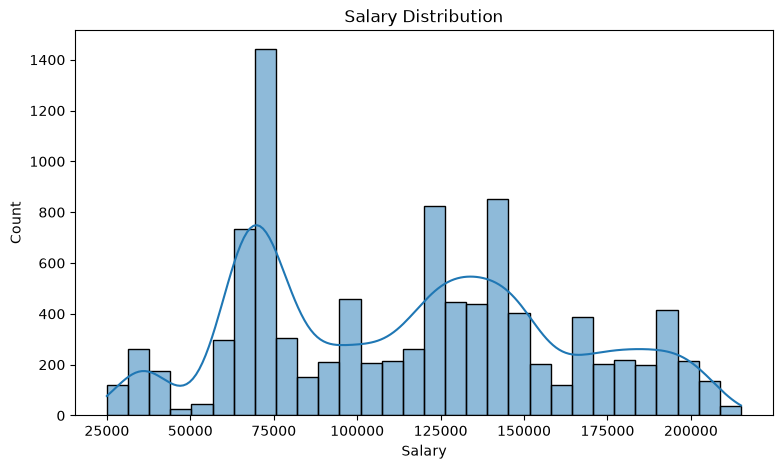

In [61]:
# Salary distribution
plt.figure(figsize=(9, 5))

sns.histplot(data=df, x="Salary", bins=30, kde=True)

plt.title("Salary Distribution")
plt.xlabel("Salary")
plt.show()

### Salary Distribution Findings

- Salary distribution is **multimodal**, with multiple peaks rather than a normal distribution.
- The highest concentration of salaries is around **70,000**.
- Additional peaks appear around **125,000–145,000**, suggesting distinct salary groups.
- Salaries range approximately from **25,000 to 215,000**.
- The noticeable peaks may reflect different job titles, experience levels, or salary structures.

**Conclusion:** Salary is not normally distributed and appears to follow distinct salary bands. Further analysis of job titles, education, and experience can help explain these patterns.

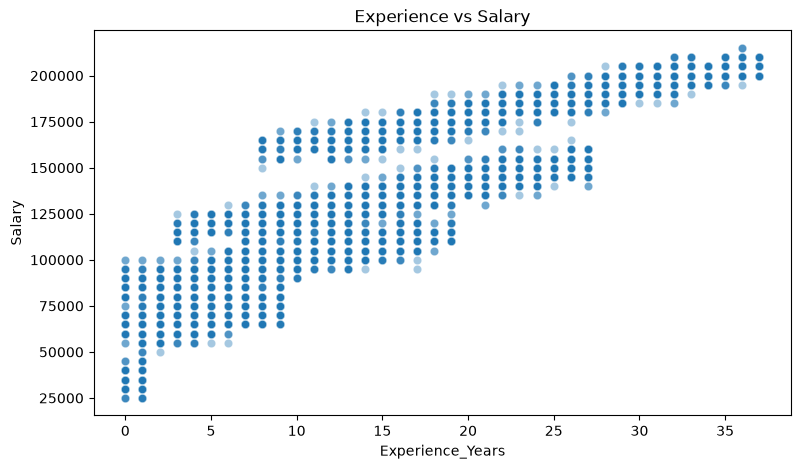

In [44]:
# Experience vs Salary
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="Experience_Years",
    y="Salary",
    alpha=0.4
)

plt.title("Experience vs Salary")
plt.show()

### Experience vs Salary Findings

- There is a **strong positive relationship** between years of experience and salary.
- Salaries generally increase as experience increases, following an approximately linear trend.
- Multiple salary bands appear at similar experience levels, indicating that experience alone does not determine salary.
- Other factors, such as job title, education level, and department, may explain these differences.
- The highly structured pattern suggests that the dataset may be synthetically generated.

**Conclusion:** Experience is an important predictor of salary. The approximately linear relationship supports using Linear Regression as a baseline model, while other features are needed to explain salary differences.

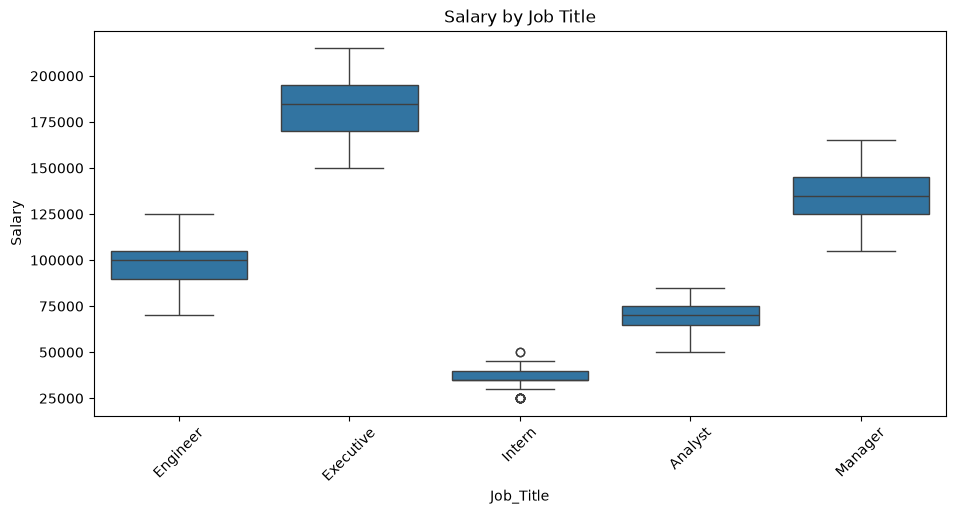

In [64]:
# Compare salary distributions across job titles
plt.figure(figsize=(11, 5))

# Display the median, quartiles, and spread of salaries
sns.boxplot(data=df, x="Job_Title", y="Salary")

# Rotate labels and adjust spacing for readability
plt.xticks(rotation=45)
plt.title("Salary by Job Title")
plt.show()

### Salary by Job Title Findings

- Salary distributions differ significantly across job titles.
- Executives have the highest typical salaries, followed by Managers, Engineers, Analysts, and Interns.
- Job title appears to be a strong predictor of salary.
- The distinct salary ranges suggest a structured salary hierarchy.

**Conclusion:** Job title is an important feature for salary prediction and should be included in model training.

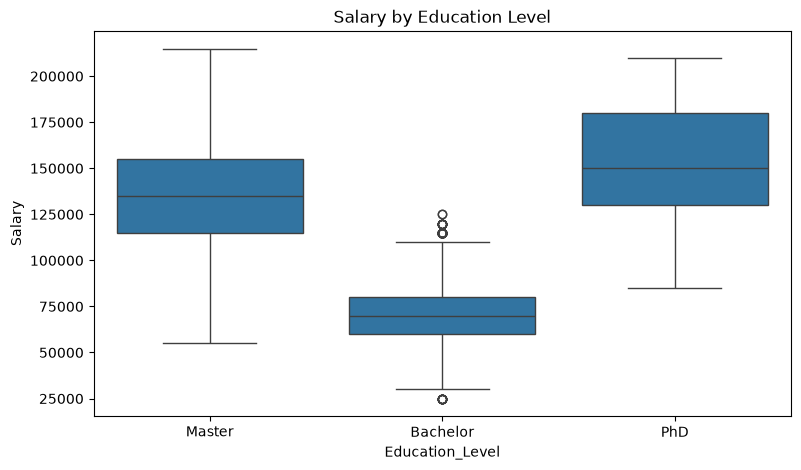

In [46]:
# Salary by education level
plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x="Education_Level", y="Salary")

plt.title("Salary by Education Level")
plt.show()

### Salary by Education Level Findings

- Employees with a **PhD** have the highest median salary (approximately 150,000).
- Master's degree holders have a median salary of approximately 135,000.
- Bachelor's degree holders have the lowest median salary (approximately 70,000).
- Some salary ranges overlap between Master's and PhD holders.
- A few outliers appear in the Bachelor's group.

**Conclusion:** Education level is an important feature for salary prediction, with higher qualifications generally associated with higher salaries in this dataset.

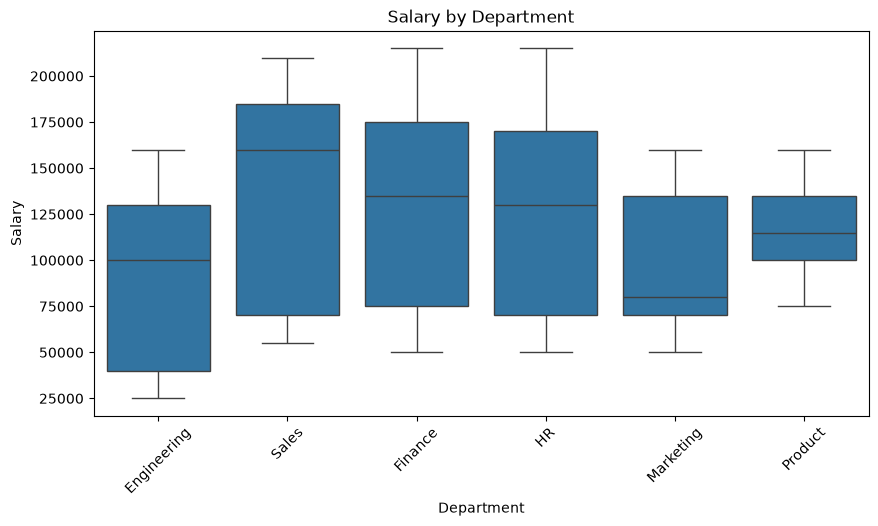

In [47]:
# Salary by department
plt.figure(figsize=(10, 5))

sns.boxplot(data=df, x="Department", y="Salary")

plt.title("Salary by Department")
plt.xticks(rotation=45)
plt.show()

### Salary by Department Findings

- **Sales** has the highest median salary (approximately 160,000).
- **Marketing** has the lowest median salary (approximately 80,000).
- Finance and HR have similar median salaries, around 130,000–135,000.
- Salary distributions overlap considerably across departments.
- Some departments show a wider salary range, indicating greater salary variation.

**Conclusion:** Department is associated with salary differences, but the substantial overlap suggests that other features, such as job title and experience, are also important for predicting salary.

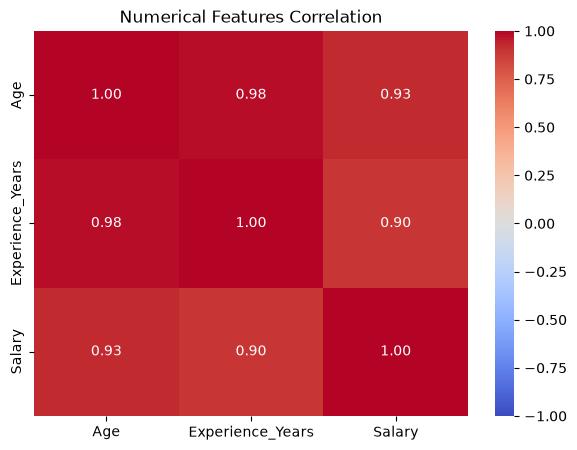

In [50]:
# Select numerical features
numeric_df = df[["Age", "Experience_Years", "Salary"]]

# Calculate correlations
corr = numeric_df.corr()

# Plot heatmap
plt.figure(figsize=(7, 5))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Numerical Features Correlation")
plt.show()

### Numerical Features Correlation Findings

- Age and salary show a strong positive correlation (r = 0.93).
- Experience and salary also show a strong positive correlation (r = 0.90).
- Age and experience are highly correlated (r = 0.98), indicating potential multicollinearity.
- These relationships support testing Linear Regression as a baseline model.

**Conclusion:** Age and experience are strongly associated with salary. However, their high correlation with each other may affect the stability and interpretation of regression coefficients.

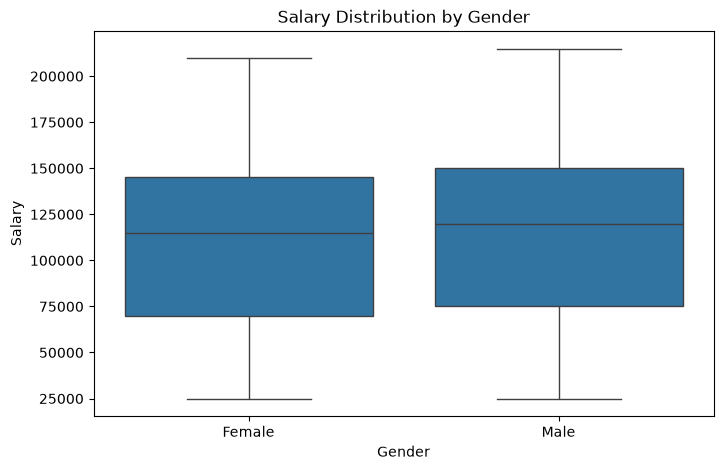

In [51]:
# Salary distribution by gender
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Gender",
    y="Salary"
)

plt.title("Salary Distribution by Gender")
plt.show()

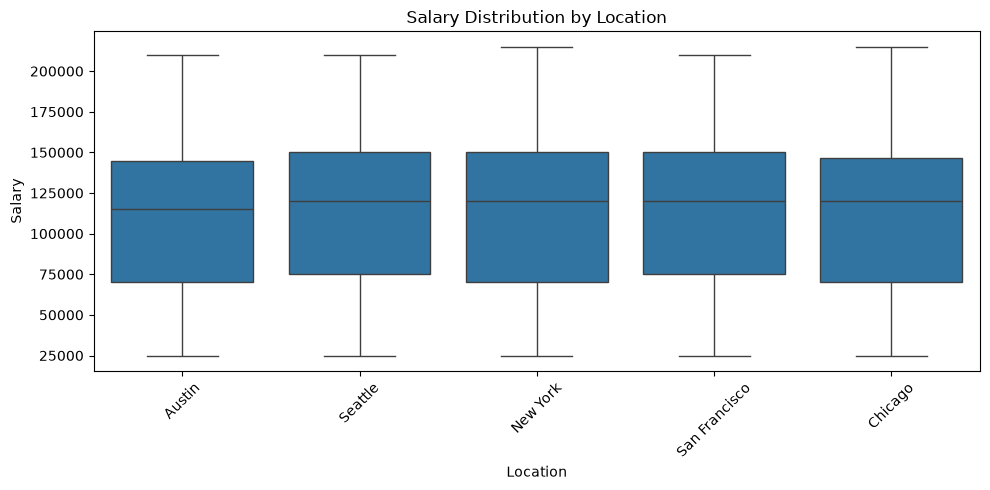

In [54]:
# Compare salary distributions across locations
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="Location",
    y="Salary"
)

plt.title("Salary Distribution by Location")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [55]:
# Compare average and median salaries by location
location_stats = df.groupby("Location")["Salary"].agg(
    Count="count",
    Mean="mean",
    Median="median"
)

display(location_stats.round(2))

,Count,Mean,Median
Location,,,
Austin,2034,113436.58,115000.0
Chicago,2008,114569.22,120000.0
New York,1980,116648.99,120000.0
San Francisco,1961,116613.97,120000.0
Seattle,2017,115708.97,120000.0


### Final EDA Findings

- Salary has a multimodal distribution.
- Salary increases strongly with experience.
- Job title and education level show clear salary differences.
- Department has overlapping salary distributions.
- Age and experience are highly correlated (r = 0.98).
- Linear Regression is a strong baseline candidate.
- Tree-based models will be compared to capture possible nonlinear relationships.